# 현실의 데이터 01: 패션 커머스: 비슷한 옷 추천

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/01_fashion_commerce.ipynb)

**분야**: 커머스 · 콘텐츠 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 개인화 추천 · 수요예측 · 재고관리 · 고객생애가치

> 옷 사진 2만 2천 장. 비슷한 옷을 골라 줄 수 있을까?

**데이터**: Fashion Product Images (Small) (약 140MB). Kaggle 'Fashion Product Images' 의 축소판, Hugging Face ashraq/fashion-product-images-small (첫 묶음 22,036장).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 상품 하나 (사진 60×80 + 성별 · 종류 · 색 · 계절) |
| ② 입력 X | 상품 사진 |
| ③ 출력 y | 비슷한 상품 5개 (추천) |
| ④ 평가지표 | 추천 5개 중 같은 종류(articleType) 비율 |
| ⑤ 기준선 | 무작위로 5개 고르기 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Fu et al. (2022) StyleGAN-Human: A Data-Centric Odyssey of Human Generation, ECCV](https://arxiv.org/abs/2204.11823)
- [데이터 원본: Fashion Product Images (Kaggle, P. Aggarwal)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-dataset)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

상품 사진과 정보가 들어 있는 parquet 파일 하나 (약 140MB). 처음엔 1분쯤 걸린다.

In [2]:
URL = "https://huggingface.co/api/datasets/ashraq/fashion-product-images-small/parquet/default/train/0.parquet"
df = pd.read_parquet(download(URL, "data/fashion_0.parquet"))
print(df.shape)
df.drop(columns="image").head()

(22036, 11)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


## 열어 보기

한 행 = 상품 하나. 어떤 종류가 많을까? 사진도 몇 장 보자.

masterCategory
Apparel           10678
Accessories        5637
Footwear           4597
Personal Care      1068
Free Items           46
Sporting Goods        9
Home                  1
Name: count, dtype: int64 

articleType
Tshirts         3515
Shirts          1600
Casual Shoes    1447
Watches         1274
Sports Shoes     984
Kurtas           923
Handbags         881
Tops             880
Heels            645
Sunglasses       548
Name: count, dtype: int64


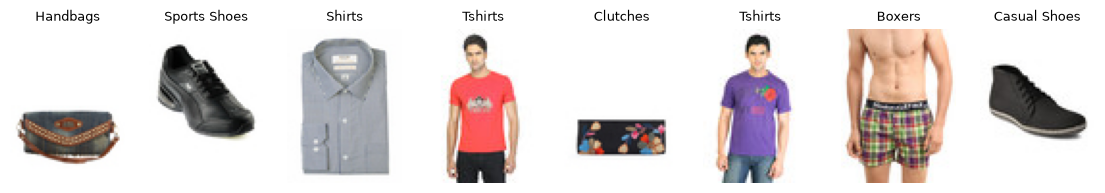

In [3]:
from PIL import Image
print(df["masterCategory"].value_counts(), "\n")
print(df["articleType"].value_counts().head(10))
fig, axs = plt.subplots(1, 8, figsize=(14, 2.6))
for ax, (_, row) in zip(axs, df.sample(8, random_state=0).iterrows()):
    ax.imshow(Image.open(io.BytesIO(row["image"]["bytes"]))); ax.set_title(row["articleType"], fontsize=9); ax.axis("off")
plt.show()

## 문제 하나 골라 보기: '이 옷과 비슷한 옷' 추천

사진을 32×32 흑백으로 줄여 숫자 1,024개로 만들고, 숫자가 가장 가까운 상품 5개를 '비슷한 옷' 으로 추천한다.
채점: 추천 5개 중 **같은 종류 (articleType)** 가 몇 개인가. 기준선: 무작위 5개.

In [4]:
from sklearn.neighbors import NearestNeighbors

def to_vector(image_bytes, size=32):
    """Image bytes -> grayscale size x size, flattened to 0~1"""
    im = Image.open(io.BytesIO(image_bytes)).convert("L").resize((size, size))
    return np.asarray(im, dtype=np.float32).ravel() / 255

items = df[df["masterCategory"] == "Apparel"].reset_index(drop=True)
V = np.stack([to_vector(b["bytes"]) for b in items["image"]])
types = items["articleType"].astype(str).to_numpy()
print("apparel items:", V.shape)

def same_type_rate(neighbors, types):
    """Share of recommended items that have the same articleType as the query"""
    return np.mean(types[neighbors] == types[:, None])

nn = NearestNeighbors(n_neighbors=6).fit(V)
neighbors = nn.kneighbors(V, return_distance=False)[:, 1:]          # drop the item itself
rng = np.random.default_rng(0)
random5 = rng.integers(0, len(items), size=(len(items), 5))
print(f"random 5           : {same_type_rate(random5, types):.0%} same type")
print(f"nearest 5 by pixels: {same_type_rate(neighbors, types):.0%} same type")

apparel items: (10678, 1024)


random 5           : 15% same type
nearest 5 by pixels: 63% same type


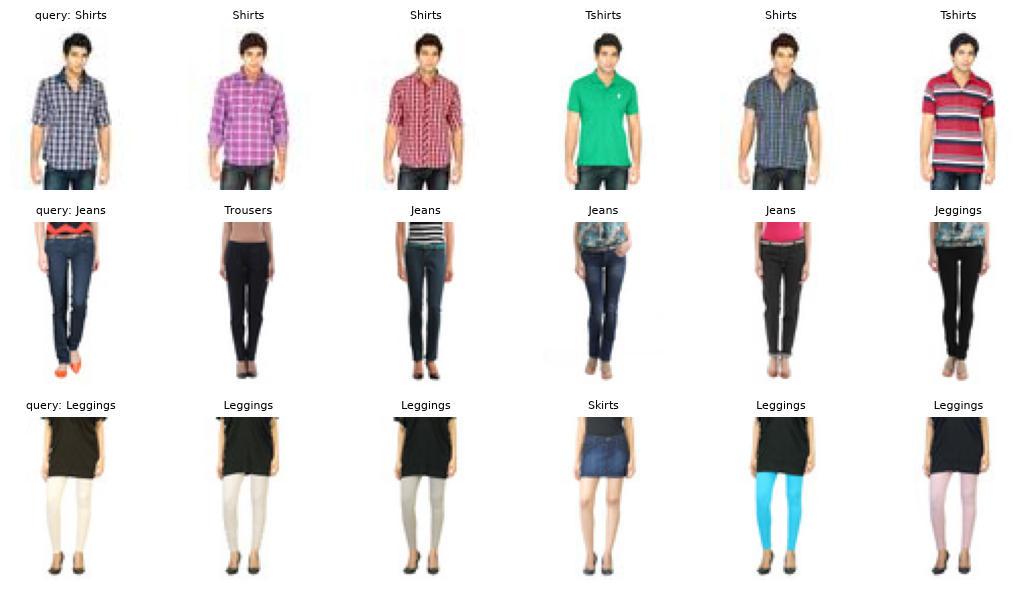

In [5]:
fig, axs = plt.subplots(3, 6, figsize=(11, 6))
for r, q in enumerate([0, 100, 2000]):
    for c, i in enumerate([q] + list(neighbors[q])):
        axs[r, c].imshow(Image.open(io.BytesIO(items["image"][i]["bytes"]))); axs[r, c].axis("off")
        axs[r, c].set_title(("query: " if c == 0 else "") + types[i], fontsize=8)
plt.tight_layout(); plt.show()

## 다른 문제로 바꿔 보기

- **수요예측 · 재고**: 이 데이터에는 판매량이 없다. **데이터에 없는 y 는 맞힐 수 없다.** 판매 기록이 있는 데이터 (예: Kaggle 'H&M Personalized Fashion Recommendations', 로그인 필요) 가 필요하다.
- **개인화 추천**: 여기서는 '사진이 비슷한 옷' 이다. 고객마다 다른 추천을 하려면 한 행이 '고객 × 상품' 인 구매 기록이 있어야 한다.
- **옷 사진 생성**: StyleGAN 으로 옷 입은 사람을 만든 연구 (StyleGAN-Human) 는 전신 사진 23만 장 SHHQ 를 썼다 (신청 필요).

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |